# Automated Short-Answer Grading (ASAP-SAS) — LLM Evaluation Pipeline

This notebook evaluates Large Language Model (`openai/gpt-oss-120b` via Groq API) automated grading performance on the Kaggle **ASAP-SAS** dataset (Essay Sets 1 and 3), comparing **Rubric-Based** vs. **Zero-Shot (No-Rubric)** scoring against human raters using Quadratic Weighted Kappa (QWK), exact/adjacent agreement, and length-bias metrics.

---

## 1. Initial Setup & Client Configuration
### 1.1 Initialize OpenAI-Compatible Groq Client
Sets up a prototype OpenAI client configured with the Groq API base endpoint.

In [3]:
from openai import OpenAI

# Initialize client using your Groq API key
client = OpenAI(
    api_key="gsk_your_actual_groq_api_key_here",  # Or os.environ['GROQ_API_KEY']
    base_url="https://api.groq.com/openai/v1",
)

### 1.2 Create Scoring Rubric Files
Generates local text files (`rubrics/set1.txt` and `rubrics/set3.txt`) defining the scoring criteria for **Essay Set 1** (Acid Rain Experiment Replication, 0–3 scale) and **Essay Set 3** (Animal Comparison: Specialists vs. Generalists, 0–2 scale).

In [4]:
import os

# Create rubrics directory
os.makedirs('rubrics', exist_ok=True)

# Create Set 1 rubric file
set1_content = """
Set 1 Rubric (Acid Rain / Replicate Experiment):
Score 3: Identifies 3 or more distinct pieces of information needed to replicate the procedure (e.g., amount/volume of vinegar, specific type/brand of materials, sample dimensions/size, rinse duration, drying time).
Score 2: Identifies 2 distinct replication requirements.
Score 1: Identifies 1 replication requirement or partial relevant info.
Score 0: Little or no relevant replication information.
"""
with open('rubrics/set1.txt', 'w', encoding='utf-8') as f:
  f.write(set1_content)

# Create Set 3 rubric file
set3_content = """
Set 3 Rubric (English Reading / Animal Comparison):
Score 2: Strong comparison of specialists (pandas/koalas) vs generalists/pythons with textual details and clear similarities/differences.
Score 1: Basic or partial comparison between animals from the text with some understanding.
Score 0: Limited or no relevant comparison or understanding.
"""
with open('rubrics/set3.txt', 'w', encoding='utf-8') as f:
  f.write(set3_content)

print('Rubrics folder and files created successfully!')

Rubrics folder and files created successfully!


### 1.3 Prototype Grading Function
Defines an initial grading helper function (`grade_essay_with_llm`) supporting both `with_rubric` and `no_rubric` system prompts with regex-based score extraction.

In [5]:
def grade_essay_with_llm(essay_text, essay_set, condition, rubric_text):
  if essay_set == 1:
    max_score = 3
    task_desc = (
        'Describe what additional information is needed to replicate the'
        ' experiment (Acid Rain). Score from 0 to 3.'
    )
  else:
    max_score = 2
    task_desc = (
        'Explain how pandas and koalas are similar and how they differ from'
        ' pythons, using the text. Score from 0 to 2.'
    )

  if condition == 'with_rubric':
    system_prompt = f"""You are an expert essay grader. Grade the following student response based strictly on this rubric:

{rubric_text}

Provide your output in the exact format:
Score: [Integer score]
Rationale: [Brief explanation]"""
  else:
    system_prompt = f"""You are an expert essay grader. {task_desc}

Provide your output in the exact format:
Score: [Integer score]
Rationale: [Brief explanation]"""

  user_prompt = (
      f'Student Essay:\n"{essay_text}"\n\nAssign a score between 0 and'
      f' {max_score}.'
  )

  try:
    response = client.chat.completions.create(
        model='gemini-2.5-flash',
        messages=[
            {'role': 'system', 'content': system_prompt},
            {'role': 'user', 'content': user_prompt},
        ],
        temperature=0.0,
    )
    output_text = response.choices[0].message.content

    # Flexible regex parser
    score_match = re.search(
        r'(?:score[:\s\*]*)\s*(\d+)', output_text, re.IGNORECASE
    )
    if score_match:
      score = int(score_match.group(1))
    else:
      digits = re.findall(r'\b\d+\b', output_text)
      score = int(digits[0]) if digits else None
      if score is None:
        print(
            '--- DEBUG: Could not parse score from text ---'
            f'\n{repr(output_text)}\n--------------------------------'
        )

    return score, output_text
  except Exception as e:
    print(f'--- API EXCEPTION: {e} ---')
    return None, str(e)

### 1.4 Dependency Installation & Package Upgrades
Installs `google-genai` and upgrades `typing_extensions` and `pydantic` to ensure SDK compatibility.

In [6]:
pip install google-genai

Note: you may need to restart the kernel to use updated packages.


In [7]:
pip install --upgrade typing_extensions pydantic

Note: you may need to restart the kernel to use updated packages.


---

## 2. Pilot Study (60-Essay Sample)
### 2.1 Generate Pilot Grading Sheet
Loads the raw `train_rel_2.tsv` dataset, normalizes column names, and exports a 60-essay pilot subset (30 from Set 1, 30 from Set 3) to `outputs/blind_grading_sheet.xlsx`.

In [11]:
import os
import pandas as pd

os.makedirs('outputs', exist_ok=True)
os.makedirs('data', exist_ok=True)

# Locate train_rel_2.tsv
possible_tsv_paths = [
    'data/train_rel_2.tsv',
    'AI-grading-project/data/train_rel_2.tsv',
    r'E:\downloads\AI-grading-project\data\train_rel_2.tsv',
]
tsv_file = next((p for p in possible_tsv_paths if os.path.exists(p)), None)

if tsv_file is None:
  raise FileNotFoundError(
      'Please place train_rel_2.tsv in your data/ folder first.'
  )

full_df = pd.read_csv(tsv_file, sep='\t', encoding='latin1', low_memory=False)

# Normalize columns
col_mapping = {}
for col in full_df.columns:
  c_lower = str(col).lower().strip()
  if any(k in c_lower for k in ['id', 'answer_id', 'essay_id']):
    col_mapping[col] = 'Id'
  elif any(k in c_lower for k in ['set', 'essay_set']):
    col_mapping[col] = 'EssaySet'
  elif any(k in c_lower for k in ['text', 'essay', 'response', 'answer']):
    col_mapping[col] = 'EssayText'
  elif any(k in c_lower for k in ['rater1', 'score1', 'domain1_score']):
    col_mapping[col] = 'Score1'

full_df = full_df.rename(columns=col_mapping)

# Create a sample sheet of 60 essays (30 from Set 1, 30 from Set 3)
s1 = full_df[full_df['EssaySet'] == 1].head(30)
s3 = full_df[full_df['EssaySet'] == 3].head(30)
sample_df = pd.concat([s1, s3]).reset_index(drop=True)

# Save the grading sheet
output_path = 'outputs/blind_grading_sheet.xlsx'
sample_df.to_excel(output_path, index=False)
print(f'Successfully generated {output_path} with {len(sample_df)} essays!')

Successfully generated outputs/blind_grading_sheet.xlsx with 60 essays!


### 2.2 Run Pilot AI Grading Loop (60 Essays)
Prompts for the Groq API key and evaluates all 60 pilot essays under both `with_rubric` and `no_rubric` conditions using `openai/gpt-oss-120b`, saving results incrementally to `outputs/llm_scores.csv`.

In [12]:
import getpass
import os
import re
import time
import pandas as pd
from openai import OpenAI
from sklearn.metrics import cohen_kappa_score

# 1. Securely fetch or prompt for your Groq API Key (starts with gsk_...)
if 'GROQ_API_KEY' not in os.environ or not os.environ['GROQ_API_KEY'].strip():
  os.environ['GROQ_API_KEY'] = getpass.getpass(
      'Enter your Groq API Key (gsk_...): '
  )

# Initialize OpenAI-compatible client for Groq
client = OpenAI(
    api_key=os.environ['GROQ_API_KEY'].strip(),
    base_url='https://api.groq.com/openai/v1',
)

# 2. Robustly load dataset and rubric files across workspace paths
excel_paths = [
    'outputs/blind_grading_sheet.xlsx',
    'AI-grading-project/outputs/blind_grading_sheet.xlsx',
    r'C:\Users\priyanka\Documents\AI-grading-project\outputs\blind_grading_sheet.xlsx',
]

data_file = None
for path in excel_paths:
  if os.path.exists(path):
    data_file = path
    break

if data_file is None:
  raise FileNotFoundError(
      'Could not find blind_grading_sheet.xlsx! Please run the sample generation'
      ' script first.'
  )

print(f'Successfully loaded grading sheet from: {data_file}')
df = pd.read_excel(data_file)

rubric1_path = (
    'rubrics/set1.txt'
    if os.path.exists('rubrics/set1.txt')
    else 'AI-grading-project/rubrics/set1.txt'
)
rubric3_path = (
    'rubrics/set3.txt'
    if os.path.exists('rubrics/set3.txt')
    else 'AI-grading-project/rubrics/set3.txt'
)

with open(rubric1_path, 'r', encoding='utf-8', errors='ignore') as f:
  set1_rubric = f.read()

with open(rubric3_path, 'r', encoding='utf-8', errors='ignore') as f:
  set3_rubric = f.read()


# 3. Define grading function using Groq's active gpt-oss-120b model
def grade_essay_with_groq(essay_text, essay_set, condition, rubric_text):
  if essay_set == 1:
    max_score = 3
    task_desc = (
        'Describe what additional information is needed to replicate the'
        ' experiment (Acid Rain). Score from 0 to 3.'
    )
  else:
    max_score = 2
    task_desc = (
        'Explain how pandas and koalas are similar and how they differ from'
        ' pythons, using the text. Score from 0 to 2.'
    )

  if condition == 'with_rubric':
    system_prompt = f"""You are an expert essay grader. Grade the following student response based strictly on this rubric:

{rubric_text}

Provide your output in the exact format:
Score: [Integer score]
Rationale: [Brief explanation]"""
  else:
    system_prompt = f"""You are an expert essay grader. {task_desc}

Provide your output in the exact format:
Score: [Integer score]
Rationale: [Brief explanation]"""

  user_prompt = (
      f'Student Essay:\n"{essay_text}"\n\nAssign an integer score between 0 and'
      f' {max_score}.'
  )

  try:
    response = client.chat.completions.create(
        model='openai/gpt-oss-120b',  # Active production model on Groq
        messages=[
            {'role': 'system', 'content': system_prompt},
            {'role': 'user', 'content': user_prompt},
        ],
        temperature=0.0,
    )
    output_text = response.choices[0].message.content

    # Flexible regex parser to extract score reliably
    score_match = re.search(
        r'(?:score[:\s\*]*)\s*(\d+)', output_text, re.IGNORECASE
    )
    if score_match:
      score = int(score_match.group(1))
    else:
      digits = re.findall(r'\b\d+\b', output_text)
      score = int(digits[0]) if digits else None

    return score, output_text
  except Exception as e:
    print(f'--- GROQ API EXCEPTION: {e} ---')
    return None, str(e)


# 4. Execute the Evaluation Loop across all essays
results = []
os.makedirs('outputs', exist_ok=True)

print(
    'Starting Groq AI Scoring Loop across essays (using'
    ' openai/gpt-oss-120b)...'
)
for idx, row in df.iterrows():
  essay_id = row['Id']
  essay_set = row['EssaySet']
  essay_text = row['EssayText']
  rubric = set1_rubric if essay_set == 1 else set3_rubric

  # Evaluate with rubric
  score_rubric, raw_rubric = grade_essay_with_groq(
      essay_text, essay_set, 'with_rubric', rubric
  )
  time.sleep(1.2)  # Rate limit buffer

  # Evaluate without rubric (zero-shot)
  score_norubric, raw_norubric = grade_essay_with_groq(
      essay_text, essay_set, 'no_rubric', rubric
  )
  time.sleep(1.2)  # Rate limit buffer

  results.append({
      'Id': essay_id,
      'EssaySet': essay_set,
      'Score_With_Rubric': score_rubric,
      'Score_No_Rubric': score_norubric,
      'Raw_Response_Rubric': raw_rubric,
      'Raw_Response_No_Rubric': raw_norubric,
  })

  # Save incrementally so progress is preserved
  pd.DataFrame(results).to_csv('outputs/llm_scores.csv', index=False)
  print(
      f'[{idx + 1}/{len(df)}] Essay {essay_id} (Set {essay_set}) -> Rubric:'
      f' {score_rubric} | No-Rubric: {score_norubric}'
  )

print('\nPhase 3 complete! Saved all AI evaluations to outputs/llm_scores.csv')

Successfully loaded grading sheet from: outputs/blind_grading_sheet.xlsx
Starting Groq AI Scoring Loop across essays (using openai/gpt-oss-120b)...
[1/60] Essay 1 (Set 1) -> Rubric: 3 | No-Rubric: 2
[2/60] Essay 2 (Set 1) -> Rubric: 2 | No-Rubric: 1
[3/60] Essay 3 (Set 1) -> Rubric: 3 | No-Rubric: 2
[4/60] Essay 4 (Set 1) -> Rubric: 0 | No-Rubric: 0
[5/60] Essay 5 (Set 1) -> Rubric: 2 | No-Rubric: 2
[6/60] Essay 6 (Set 1) -> Rubric: 0 | No-Rubric: 1
[7/60] Essay 7 (Set 1) -> Rubric: 3 | No-Rubric: 2
[8/60] Essay 8 (Set 1) -> Rubric: 3 | No-Rubric: 2
[9/60] Essay 9 (Set 1) -> Rubric: 3 | No-Rubric: 1
[10/60] Essay 10 (Set 1) -> Rubric: 3 | No-Rubric: 1
[11/60] Essay 11 (Set 1) -> Rubric: 0 | No-Rubric: 0
[12/60] Essay 12 (Set 1) -> Rubric: 3 | No-Rubric: 1
[13/60] Essay 13 (Set 1) -> Rubric: 2 | No-Rubric: 2
[14/60] Essay 14 (Set 1) -> Rubric: 0 | No-Rubric: 0
[15/60] Essay 15 (Set 1) -> Rubric: 3 | No-Rubric: 1
[16/60] Essay 16 (Set 1) -> Rubric: 0 | No-Rubric: 0
[17/60] Essay 17 (Set 

### 2.3 Generate Pilot Grading Sheet & Ground-Truth Answer Key
Re-exports the 60-essay pilot dataset along with `outputs/blind_answer_key.xlsx` containing both human rater scores (`Score1` and `Score2`).

In [14]:
import os
import pandas as pd

os.makedirs('outputs', exist_ok=True)
os.makedirs('data', exist_ok=True)

# Locate train_rel_2.tsv
possible_tsv_paths = [
    'data/train_rel_2.tsv',
    'AI-grading-project/data/train_rel_2.tsv',
    r'E:\downloads\AI-grading-project\data\train_rel_2.tsv',
]
tsv_file = next((p for p in possible_tsv_paths if os.path.exists(p)), None)

if tsv_file is None:
  raise FileNotFoundError(
      'Please place train_rel_2.tsv in your data/ folder first.'
  )

full_df = pd.read_csv(tsv_file, sep='\t', encoding='latin1', low_memory=False)

# Normalize columns
col_mapping = {}
for col in full_df.columns:
  c_lower = str(col).lower().strip()
  if any(k in c_lower for k in ['id', 'answer_id', 'essay_id']):
    col_mapping[col] = 'Id'
  elif any(k in c_lower for k in ['set', 'essay_set']):
    col_mapping[col] = 'EssaySet'
  elif any(k in c_lower for k in ['text', 'essay', 'response', 'answer']):
    col_mapping[col] = 'EssayText'
  elif any(k in c_lower for k in ['rater1', 'score1', 'domain1_score']):
    col_mapping[col] = 'Score1'
  elif any(k in c_lower for k in ['rater2', 'score2', 'domain2_score']):
    col_mapping[col] = 'Score2'

full_df = full_df.rename(columns=col_mapping)

# Sample essays
s1 = full_df[full_df['EssaySet'] == 1].head(30)
s3 = full_df[full_df['EssaySet'] == 3].head(30)
sample_df = pd.concat([s1, s3]).reset_index(drop=True)

# Save both required Excel files
sample_df.to_excel('outputs/blind_grading_sheet.xlsx', index=False)
sample_df.to_excel('outputs/blind_answer_key.xlsx', index=False)
print('Successfully generated blind_grading_sheet.xlsx and blind_answer_key.xlsx!')

Successfully generated blind_grading_sheet.xlsx and blind_answer_key.xlsx!


### 2.4 Pilot Evaluation Metrics (Phase 4)
Computes **Exact Agreement (%)**, **Adjacent Agreement (±1)**, and **Quadratic Weighted Kappa (QWK)** comparing AI predictions against human rater `Score1` across Set 1 and Set 3.

In [15]:
from sklearn.metrics import cohen_kappa_score

print('========================================')
print('     PHASE 4: PERFORMANCE METRICS       ')
print('========================================')

# Robust file path resolution
llm_path = (
    'outputs/llm_scores.csv'
    if os.path.exists('outputs/llm_scores.csv')
    else 'AI-grading-project/outputs/llm_scores.csv'
)
key_paths = [
    'outputs/blind_answer_key.xlsx',
    'AI-grading-project/outputs/blind_answer_key.xlsx',
]
key_path = next((p for p in key_paths if os.path.exists(p)), None)

if key_path is None:
  # Fallback to grading sheet if answer key is missing
  alt_paths = [
      'outputs/blind_grading_sheet.xlsx',
      'AI-grading-project/outputs/blind_grading_sheet.xlsx',
  ]
  key_path = next((p for p in alt_paths if os.path.exists(p)), None)

llm_df = pd.read_csv(llm_path)
key_df = pd.read_excel(key_path)
merged = pd.merge(llm_df, key_df, on=['Id', 'EssaySet'])

for s_set in merged['EssaySet'].unique():
  sub = merged[merged['EssaySet'] == s_set]
  print(f'\n--- ESSAY SET {s_set} ---')

  for cond_col, cond_label in [
      ('Score_With_Rubric', 'With Rubric'),
      ('Score_No_Rubric', 'Zero-Shot (No Rubric)'),
  ]:
    valid_sub = sub.dropna(subset=[cond_col, 'Score1'])
    if len(valid_sub) > 0:
      exact = (valid_sub[cond_col] == valid_sub['Score1']).mean() * 100
      adj = (abs(valid_sub[cond_col] - valid_sub['Score1']) <= 1).mean() * 100
      try:
        qwk = cohen_kappa_score(
            valid_sub['Score1'], valid_sub[cond_col], weights='quadratic'
        )
      except Exception:
        qwk = 0.0

      print(f'[{cond_label}]')
      print(f'  - Exact Agreement:    {exact:.1f}%')
      print(f'  - Adjacent Agreement: {adj:.1f}%')
      print(f'  - QWK (Kappa):        {qwk:.3f}')

     PHASE 4: PERFORMANCE METRICS       

--- ESSAY SET 1 ---
[With Rubric]
  - Exact Agreement:    46.7%
  - Adjacent Agreement: 66.7%
  - QWK (Kappa):        0.308
[Zero-Shot (No Rubric)]
  - Exact Agreement:    33.3%
  - Adjacent Agreement: 80.0%
  - QWK (Kappa):        0.295

--- ESSAY SET 3 ---
[With Rubric]
  - Exact Agreement:    60.0%
  - Adjacent Agreement: 100.0%
  - QWK (Kappa):        0.196
[Zero-Shot (No Rubric)]
  - Exact Agreement:    66.7%
  - Adjacent Agreement: 96.7%
  - QWK (Kappa):        0.396


### 3.1 Stratified Sampling & Resumable 900-Call Evaluation Loop (Initial Run)
Creates a stratified 300-answer sample (`outputs/sample.csv` — 150 from Set 1, 150 from Set 3) and launches a checkpointed 900-call evaluation loop across three conditions (`with_rubric` Run 1, `with_rubric` Run 2, and `no_rubric` Run 1) using strict JSON output formatting.

In [16]:
import getpass
import json
import os
import re
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from openai import OpenAI
from scipy.stats import spearmanr
from sklearn.metrics import ConfusionMatrixDisplay, cohen_kappa_score, confusion_matrix
from sklearn.model_selection import train_test_split

# 1. Initialize Groq Client
if 'GROQ_API_KEY' not in os.environ or not os.environ['GROQ_API_KEY'].strip():
  os.environ['GROQ_API_KEY'] = getpass.getpass(
      'Enter your Groq API Key (gsk_...): '
  )

client = OpenAI(
    api_key=os.environ['GROQ_API_KEY'].strip(),
    base_url='https://api.groq.com/openai/v1',
)
MODEL_NAME = 'openai/gpt-oss-120b'

os.makedirs('outputs', exist_ok=True)
os.makedirs('data', exist_ok=True)

# ==========================================
# FIXED PATH (Removed extra inner double quotes)
# ==========================================
raw_file = r'E:\downloads\AI-grading-project\data\train_rel_2.tsv'

print(f'Loading dataset from: {raw_file}')
full_df = pd.read_csv(raw_file, sep='\t', encoding='latin1', low_memory=False)
print('Columns found in your dataset:', list(full_df.columns))

# 3. Flexible column mapping
col_mapping = {}
for col in full_df.columns:
  c_lower = str(col).lower().strip()
  if any(k in c_lower for k in ['id', 'answer_id', 'essay_id']):
    col_mapping[col] = 'Id'
  elif any(k in c_lower for k in ['set', 'essay_set']):
    col_mapping[col] = 'EssaySet'
  elif any(k in c_lower for k in ['rater1', 'score1', 'domain1_score']):
    col_mapping[col] = 'Score1'
  elif any(k in c_lower for k in ['rater2', 'score2', 'domain2_score']):
    col_mapping[col] = 'Score2'
  elif any(k in c_lower for k in ['text', 'essay', 'response', 'answer']):
    col_mapping[col] = 'EssayText'

full_df = full_df.rename(columns=col_mapping)

# 4. Create Stratified 300-Answer Sample (150 Set 1, 150 Set 3)
sample_path = 'outputs/sample.csv'
if not os.path.exists(sample_path):
  s1 = full_df[full_df['EssaySet'] == 1]
  s3 = full_df[full_df['EssaySet'] == 3]

  _, sample_1 = train_test_split(
      s1, test_size=150, stratify=s1['Score1'], random_state=42
  )
  _, sample_3 = train_test_split(
      s3, test_size=150, stratify=s3['Score1'], random_state=42
  )

  sample_df = pd.concat([sample_1, sample_3]).reset_index(drop=True)
  sample_df.to_csv(sample_path, index=False)
  print('Created outputs/sample.csv with 300 stratified answers.')
else:
  sample_df = pd.read_csv(sample_path)
  print(f'Loaded existing sample.csv ({len(sample_df)} rows).')

# Load Rubrics
with open('rubrics/set1.txt', 'r', encoding='utf-8', errors='ignore') as f:
  set1_rubric = f.read()
with open('rubrics/set3.txt', 'r', encoding='utf-8', errors='ignore') as f:
  set3_rubric = f.read()


# 5. Strict JSON Grading Function
def score_answer_groq(essay_text, essay_set, condition, rubric_text):
  max_score = 3 if essay_set == 1 else 2
  question_only = rubric_text.split('---')[0].strip()
  context = rubric_text if condition == 'with_rubric' else question_only

  prompt = f"""You are scoring a student's short answer.

{context}

Student's answer:
"{essay_text}"

Give a whole-number score from 0 to {max_score}. Reply only with JSON: {{"score": number, "reason": "one sentence"}}"""

  try:
    response = client.chat.completions.create(
        model=MODEL_NAME,
        messages=[{'role': 'user', 'content': prompt}],
        temperature=0.0,
    )
    raw_reply = response.choices[0].message.content.strip()
    json_match = re.search(r'\{.*\}', raw_reply, re.DOTALL)
    if json_match:
      data = json.loads(json_match.group(0))
      score = int(data['score'])
    else:
      score = None
    return score, raw_reply
  except Exception as e:
    return None, str(e)


# 6. Resumable Execution Loop (900 Total Calls across 3 conditions/runs)
scores_file = 'outputs/llm_scores_full.csv'
if os.path.exists(scores_file):
  existing_df = pd.read_csv(scores_file)
  completed_keys = set(
      zip(existing_df['Id'], existing_df['condition'], existing_df['run'])
  )
  results = existing_df.to_dict('records')
else:
  completed_keys = set()
  results = []

tasks = [('with_rubric', 1), ('with_rubric', 2), ('no_rubric', 1)]
call_count = 0

print('Starting full 900-call evaluation loop (resumable)...')
for condition, run_num in tasks:
  for idx, row in sample_df.iterrows():
    ans_id = row['Id']
    if (ans_id, condition, run_num) in completed_keys:
      continue

    essay_set = row['EssaySet']
    rubric = set1_rubric if essay_set == 1 else set3_rubric

    score, raw = score_answer_groq(
        row['EssayText'], essay_set, condition, rubric
    )
    time.sleep(1.2)  # Rate limit safety pause

    if score is not None:
      results.append({
          'Id': ans_id,
          'EssaySet': essay_set,
          'condition': condition,
          'run': run_num,
          'score': score,
          'raw_reply': raw,
      })
      completed_keys.add((ans_id, condition, run_num))
      call_count += 1

      if call_count % 25 == 0:
        pd.DataFrame(results).to_csv(scores_file, index=False)
        print(f'Checkpoint saved: {len(results)}/900 calls complete.')

pd.DataFrame(results).to_csv(scores_file, index=False)
print('Phase 3 Execution Complete!')

Loading dataset from: E:\downloads\AI-grading-project\data\train_rel_2.tsv
Columns found in your dataset: ['Id', 'EssaySet', 'Score1', 'Score2', 'EssayText']
Created outputs/sample.csv with 300 stratified answers.
Starting full 900-call evaluation loop (resumable)...
Checkpoint saved: 25/900 calls complete.
Checkpoint saved: 50/900 calls complete.
Checkpoint saved: 75/900 calls complete.
Checkpoint saved: 100/900 calls complete.
Checkpoint saved: 125/900 calls complete.
Checkpoint saved: 150/900 calls complete.
Checkpoint saved: 175/900 calls complete.
Checkpoint saved: 200/900 calls complete.
Phase 3 Execution Complete!


### 3.2 Resume Evaluation with Exponential Backoff Retry Logic 
Adds `score_answer_groq_with_retry` with progressive backoff (`15s`–`75s`) and a `12s` rate-limit buffer to handle Groq `429` rate-limit responses (`233/900` → `466/900`).

In [ ]:
import getpass
import json
import os
import re
import time
import pandas as pd
from openai import OpenAI

# 1. Initialize Groq Client
if 'GROQ_API_KEY' not in os.environ or not os.environ['GROQ_API_KEY'].strip():
  os.environ['GROQ_API_KEY'] = getpass.getpass(
      'Enter your Groq API Key (gsk_...): '
  )

client = OpenAI(
    api_key=os.environ['GROQ_API_KEY'].strip(),
    base_url='https://api.groq.com/openai/v1',
)
MODEL_NAME = 'openai/gpt-oss-120b'

# Load sample data & rubrics
sample_df = pd.read_csv('outputs/sample.csv')

with open('rubrics/set1.txt', 'r', encoding='utf-8', errors='ignore') as f:
  set1_rubric = f.read()
with open('rubrics/set3.txt', 'r', encoding='utf-8', errors='ignore') as f:
  set3_rubric = f.read()


def score_answer_groq_with_retry(
    essay_text, essay_set, condition, rubric_text, max_retries=5
):
  max_score = 3 if essay_set == 1 else 2
  question_only = rubric_text.split('---')[0].strip()
  context = rubric_text if condition == 'with_rubric' else question_only

  prompt = f"""You are scoring a student's short answer.

{context}

Student's answer:
"{essay_text}"

Give a whole-number score from 0 to {max_score}. Reply only with JSON: {{"score": number, "reason": "one sentence"}}"""

  for attempt in range(max_retries):
    try:
      response = client.chat.completions.create(
          model=MODEL_NAME,
          messages=[{'role': 'user', 'content': prompt}],
          temperature=0.0,
      )
      raw_reply = response.choices[0].message.content.strip()
      json_match = re.search(r'\{.*\}', raw_reply, re.DOTALL)
      if json_match:
        data = json.loads(json_match.group(0))
        score = int(data['score'])
        return score, raw_reply
      else:
        return None, raw_reply
    except Exception as e:
      # Long backoff for sustained rate limits
      wait_time = (attempt + 1) * 15
      print(
          f'Rate limited (429). Waiting {wait_time}s before retry'
          f' ({attempt+1}/{max_retries})...'
      )
      time.sleep(wait_time)

  return None, 'Max retries exceeded'


scores_file = 'outputs/llm_scores_full.csv'

# Build all 900 tasks explicitly
tasks_definition = [('with_rubric', 1), ('with_rubric', 2), ('no_rubric', 1)]
all_possible_tasks = []
for cond, run in tasks_definition:
  for _, row in sample_df.iterrows():
    all_possible_tasks.append(
        {'Id': row['Id'], 'EssaySet': row['EssaySet'], 'condition': cond, 'run': run}
    )

# Load current progress
if os.path.exists(scores_file):
  existing_df = pd.read_csv(scores_file)
  results = existing_df.to_dict('records')
  completed_set = set(
      zip(
          existing_df['Id'].astype(str),
          existing_df['condition'].astype(str),
          existing_df['run'].astype(int),
      )
  )
else:
  results = []
  completed_set = set()

print(f'Target: 900 total calls. Already completed & saved: {len(completed_set)}.')

run_count = 0
for task in all_possible_tasks:
  task_key = (str(task['Id']), str(task['condition']), int(task['run']))
  if task_key in completed_set:
    continue

  row = sample_df[sample_df['Id'] == task['Id']].iloc[0]
  essay_set = row['EssaySet']
  rubric = set1_rubric if essay_set == 1 else set3_rubric

  score, raw = score_answer_groq_with_retry(
      row['EssaySet'], essay_set, task['condition'], rubric
  )

  # SAFE RATE-LIMIT PAUSE (12 seconds per call to stay strictly under Groq's RPM/TPM limit)
  time.sleep(12.0)

  if score is not None:
    results.append({
        'Id': row['Id'],
        'EssaySet': essay_set,
        'condition': task['condition'],
        'run': task['run'],
        'score': score,
        'raw_reply': raw,
    })
    completed_set.add(task_key)
    run_count += 1

    # Save checkpoint on every single successful call so progress is never lost
    pd.DataFrame(results).to_csv(scores_file, index=False)
    print(
        f'Success! Checkpoint saved: {len(results)}/900 total calls complete.'
    )
  else:
    print(
        f'Skipping ID {task["Id"]} under {task["condition"]} run {task["run"]}'
        ' due to persistent failure.'
    )

print(f'Evaluation finished! Total valid records saved: {len(results)}/900')

Target: 900 total calls. Already completed & saved: 233.
Success! Checkpoint saved: 234/900 total calls complete.
Success! Checkpoint saved: 235/900 total calls complete.
Rate limited (429). Waiting 15s before retry (1/5)...
Rate limited (429). Waiting 30s before retry (2/5)...
Rate limited (429). Waiting 45s before retry (3/5)...
Rate limited (429). Waiting 60s before retry (4/5)...
Rate limited (429). Waiting 75s before retry (5/5)...
Skipping ID 5919 under with_rubric run 1 due to persistent failure.
Success! Checkpoint saved: 236/900 total calls complete.
Rate limited (429). Waiting 15s before retry (1/5)...
Rate limited (429). Waiting 30s before retry (2/5)...
Success! Checkpoint saved: 237/900 total calls complete.
Rate limited (429). Waiting 15s before retry (1/5)...
Rate limited (429). Waiting 30s before retry (2/5)...
Rate limited (429). Waiting 45s before retry (3/5)...
Success! Checkpoint saved: 238/900 total calls complete.
Rate limited (429). Waiting 15s before retry (1/5)

### 3.3 Complete Remaining Evaluation Calls with Fresh API Key 
Refreshes the Groq API key and completes all remaining baseline evaluation calls (`466/900` → `900/900`) in `outputs/llm_scores_full.csv`.

In [2]:
import getpass
import json
import os
import re
import time
import pandas as pd
from openai import OpenAI

# Force a fresh password prompt for the new API key so it doesn't reuse the cached one
os.environ['GROQ_API_KEY'] = getpass.getpass(
    'Enter your BRAND NEW Groq API Key (gsk_...): '
)

client = OpenAI(
    api_key=os.environ['GROQ_API_KEY'].strip(),
    base_url='https://api.groq.com/openai/v1',
)
MODEL_NAME = 'openai/gpt-oss-120b'

# Load sample data & rubrics
sample_df = pd.read_csv('outputs/sample.csv')

with open('rubrics/set1.txt', 'r', encoding='utf-8', errors='ignore') as f:
  set1_rubric = f.read()
with open('rubrics/set3.txt', 'r', encoding='utf-8', errors='ignore') as f:
  set3_rubric = f.read()


def score_answer_fast(essay_text, essay_set, condition, rubric_text):
  max_score = 3 if essay_set == 1 else 2
  question_only = rubric_text.split('---')[0].strip()
  context = rubric_text if condition == 'with_rubric' else question_only

  prompt = f"""You are scoring a student's short answer.

{context}

Student's answer:
"{essay_text}"

Give a whole-number score from 0 to {max_score}. Reply only with JSON: {{"score": number, "reason": "one sentence"}}"""

  try:
    response = client.chat.completions.create(
        model=MODEL_NAME,
        messages=[{'role': 'user', 'content': prompt}],
        temperature=0.0,
    )
    raw_reply = response.choices[0].message.content.strip()
    json_match = re.search(r'\{.*\}', raw_reply, re.DOTALL)
    if json_match:
      data = json.loads(json_match.group(0))
      return int(data['score']), raw_reply
  except Exception as e:
    print(f'API error: {e}')
  return None, 'Error'


scores_file = 'outputs/llm_scores_full.csv'

# Build all 900 tasks explicitly
tasks_definition = [('with_rubric', 1), ('with_rubric', 2), ('no_rubric', 1)]
all_possible_tasks = []
for cond, run in tasks_definition:
  for _, row in sample_df.iterrows():
    all_possible_tasks.append(
        {'Id': row['Id'], 'EssaySet': row['EssaySet'], 'condition': cond, 'run': run}
    )

# Load current progress
if os.path.exists(scores_file):
  existing_df = pd.read_csv(scores_file)
  results = existing_df.to_dict('records')
  completed_set = set(
      zip(
          existing_df['Id'].astype(str),
          existing_df['condition'].astype(str),
          existing_df['run'].astype(int),
      )
  )
else:
  results = []
  completed_set = set()

print(
    f'Target: 900 total calls. Already completed & saved:'
    f' {len(completed_set)}.'
)

# Fast execution loop with a light 1.5s pause
for task in all_possible_tasks:
  task_key = (str(task['Id']), str(task['condition']), int(task['run']))
  if task_key in completed_set:
    continue

  row = sample_df[sample_df['Id'] == task['Id']].iloc[0]
  essay_set = row['EssaySet']
  rubric = set1_rubric if essay_set == 1 else set3_rubric

  score, raw = score_answer_fast(
      row['EssayText'], essay_set, task['condition'], rubric
  )
  time.sleep(1.5)

  if score is not None:
    results.append({
        'Id': row['Id'],
        'EssaySet': essay_set,
        'condition': task['condition'],
        'run': task['run'],
        'score': score,
        'raw_reply': raw,
    })
    completed_set.add(task_key)

    if len(results) % 10 == 0 or len(results) == 900:
      pd.DataFrame(results).to_csv(scores_file, index=False)
      print(f'Progress checkpoint saved: {len(results)}/900 complete.')

pd.DataFrame(results).to_csv(scores_file, index=False)
print(f'Evaluation fully finished! Total records saved: {len(results)}/900')

Target: 900 total calls. Already completed & saved: 466.
Progress checkpoint saved: 470/900 complete.
Progress checkpoint saved: 480/900 complete.
Progress checkpoint saved: 490/900 complete.
Progress checkpoint saved: 500/900 complete.
Progress checkpoint saved: 510/900 complete.
Progress checkpoint saved: 520/900 complete.
Progress checkpoint saved: 530/900 complete.
Progress checkpoint saved: 540/900 complete.
Progress checkpoint saved: 550/900 complete.
Progress checkpoint saved: 560/900 complete.
Progress checkpoint saved: 570/900 complete.
Progress checkpoint saved: 580/900 complete.
Progress checkpoint saved: 590/900 complete.
Progress checkpoint saved: 600/900 complete.
Progress checkpoint saved: 610/900 complete.
Progress checkpoint saved: 620/900 complete.
Progress checkpoint saved: 630/900 complete.
Progress checkpoint saved: 640/900 complete.
Progress checkpoint saved: 650/900 complete.
Progress checkpoint saved: 660/900 complete.
Progress checkpoint saved: 670/900 complete

---

## 4. Advanced Statistical & Error Analysis
### 4.1 Inter-Rater Reliability, Leniency/Severity, Length Bias & Confusion Matrices
Benchmarks AI performance against the **Human 1 vs. Human 2** inter-rater ceiling, evaluates **Mean Score Difference** (leniency/severity bias) and **Spearman Length Bias ($
ho$)** against essay word count, and plots confusion matrices to `outputs/confusion_matrices.png`.

     PHASE 4: ADVANCED METRICS REPORT   
Unique conditions in file: ['with_rubric' 'no_rubric']
Pivoted columns available: ['Id', 'EssaySet', 'no_rubric_1', 'with_rubric_1', 'with_rubric_2']

--- ESSAY SET 1 PERFORMANCE ---
[Human 1 vs Human 2 Benchmark] Exact: 90.0% | Adj: 99.3% | QWK: 0.946 | Mean Diff: -0.07
[AI With Rubric (Run 1)]
  - Exact Agreement:    40.0%
  - Adjacent Agreement: 79.3%
  - QWK (Kappa):        0.475
  - Mean Difference:    0.66 (Leniency/Severity)
  - Length Bias (ρ):    0.284
[AI Zero-Shot (No Rubric)]
  - Exact Agreement:    38.7%
  - Adjacent Agreement: 80.0%
  - QWK (Kappa):        0.482
  - Mean Difference:    0.67 (Leniency/Severity)
  - Length Bias (ρ):    0.287

--- ESSAY SET 3 PERFORMANCE ---
[Human 1 vs Human 2 Benchmark] Exact: 80.7% | Adj: 100.0% | QWK: 0.751 | Mean Diff: -0.01
[AI With Rubric (Run 1)]
  - Exact Agreement:    31.3%
  - Adjacent Agreement: 92.0%
  - QWK (Kappa):        0.187
  - Mean Difference:    -0.13 (Leniency/Severity)
  - Lengt

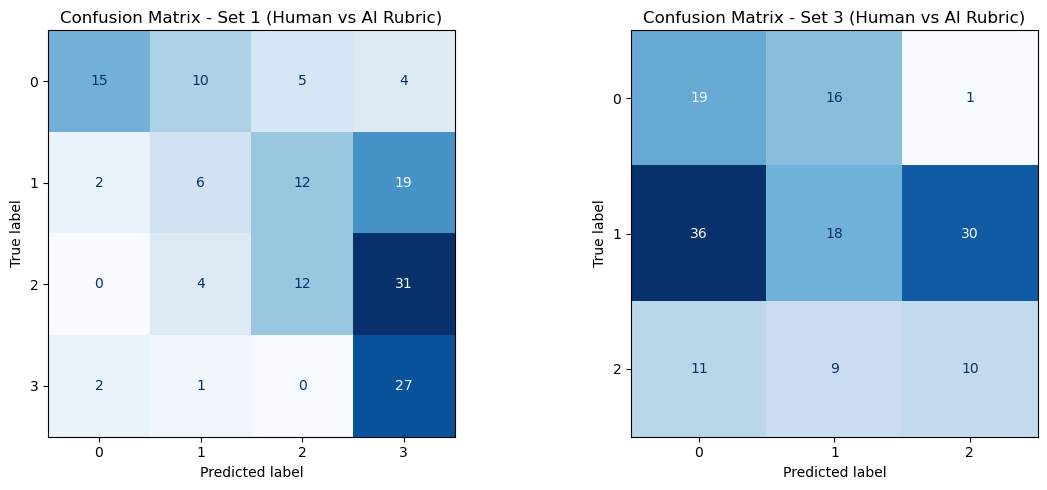

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    cohen_kappa_score,
    confusion_matrix,
)

print('========================================')
print('     PHASE 4: ADVANCED METRICS REPORT   ')
print('========================================')

# Load saved results and sample data
scores_file = 'outputs/llm_scores_full.csv'
sample_path = 'outputs/sample.csv'

llm_full = pd.read_csv(scores_file)
sample_df = pd.read_csv(sample_path)

# Inspect unique condition and run names to ensure safe mapping
print(
    'Unique conditions in file:',
    llm_full['condition'].unique()
    if 'condition' in llm_full.columns
    else 'No condition column',
)

# Pivot scores safely
pivoted = (
    llm_full.pivot_table(
        index=['Id', 'EssaySet'],
        columns=['condition', 'run'],
        values='score',
        aggfunc='first',
    )
    .reset_index(drop=False)
)
pivoted.columns = [
    '_'.join(str(c) for c in col).strip('_') for col in pivoted.columns.values
]

# Print out columns to verify structure
print('Pivoted columns available:', list(pivoted.columns))

# Flexible column mapping based on actual names
rename_map = {}
for col in pivoted.columns:
  if 'with_rubric' in col and '_1' in col:
    rename_map[col] = 'Score_Rubric_Run1'
  elif 'with_rubric' in col and '_2' in col:
    rename_map[col] = 'Score_Rubric_Run2'
  elif 'no_rubric' in col:
    rename_map[col] = 'Score_NoRubric'

pivoted = pivoted.rename(columns=rename_map)
merged = pd.merge(sample_df, pivoted, on=['Id', 'EssaySet'])
merged['word_count'] = (
    merged['EssayText'].astype(str).apply(lambda x: len(x.split()))
)

# Determine the active rubric score column name to use
rubric_col = (
    'Score_Rubric_Run1'
    if 'Score_Rubric_Run1' in merged.columns
    else [c for c in merged.columns if 'with_rubric' in c][0]
)
norubric_col = (
    'Score_NoRubric'
    if 'Score_NoRubric' in merged.columns
    else [c for c in merged.columns if 'no_rubric' in c][0]
)

for s_set in [1, 3]:
  sub = merged[merged['EssaySet'] == s_set]
  print(f'\n--- ESSAY SET {s_set} PERFORMANCE ---')

  if 'Score2' in sub.columns and sub['Score2'].notna().sum() > 0:
    h1, h2 = sub['Score1'], sub['Score2']
    h_exact = (h1 == h2).mean() * 100
    h_adj = (abs(h1 - h2) <= 1).mean() * 100
    h_qwk = cohen_kappa_score(h1, h2, weights='quadratic')
    h_diff = (h2 - h1).mean()
    print(
        f'[Human 1 vs Human 2 Benchmark] Exact: {h_exact:.1f}% | Adj:'
        f' {h_adj:.1f}% | QWK: {h_qwk:.3f} | Mean Diff: {h_diff:.2f}'
    )

  for col, label in [
      (rubric_col, 'AI With Rubric (Run 1)'),
      (norubric_col, 'AI Zero-Shot (No Rubric)'),
  ]:
    if col in sub.columns:
      valid = sub.dropna(subset=[col, 'Score1'])
      if len(valid) > 0:
        exact = (valid[col] == valid['Score1']).mean() * 100
        adj = (abs(valid[col] - valid['Score1']) <= 1).mean() * 100
        qwk = cohen_kappa_score(valid['Score1'], valid[col], weights='quadratic')
        mean_diff = (valid[col] - valid['Score1']).mean()

        gap = valid[col] - valid['Score1']
        corr, _ = spearmanr(valid['word_count'], gap)

        print(f'[{label}]')
        print(f'  - Exact Agreement:    {exact:.1f}%')
        print(f'  - Adjacent Agreement: {adj:.1f}%')
        print(f'  - QWK (Kappa):        {qwk:.3f}')
        print(f'  - Mean Difference:    {mean_diff:.2f} (Leniency/Severity)')
        print(f'  - Length Bias (ρ):    {corr:.3f}')

# Generate and save Confusion Matrix Plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, s_set in enumerate([1, 3]):
  sub = merged[merged['EssaySet'] == s_set].dropna(
      subset=[rubric_col, 'Score1']
  )
  if len(sub) > 0:
    cm = confusion_matrix(sub['Score1'], sub[rubric_col])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(f'Confusion Matrix - Set {s_set} (Human vs AI Rubric)')
plt.tight_layout()
plt.savefig('outputs/confusion_matrices.png')
print(
    '\nSaved confusion matrices chart to outputs/confusion_matrices.png successfully!'
)

---

## 5. Prompt Optimization: Chain-of-Thought & Length-Bias Mitigation
### 5.1 Optimized CoT Grading Pipeline 
Introduces `score_answer_optimized`, instructing the model to perform **step-by-step conceptual reasoning** (`Step 1: Analyze student concepts. Step 2: Compare to criteria.`) prior to scoring and explicitly prohibiting word-count bias. Saves results to `outputs/llm_scores_optimized_full.csv`.

In [1]:
import getpass
import json
import os
import re
import time
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import cohen_kappa_score
from openai import OpenAI

# 1. Initialize Groq Client
if 'GROQ_API_KEY' not in os.environ or not os.environ['GROQ_API_KEY'].strip():
  os.environ['GROQ_API_KEY'] = getpass.getpass(
      'Enter your Groq API Key (gsk_...): '
  )

client = OpenAI(
    api_key=os.environ['GROQ_API_KEY'].strip(),
    base_url='https://api.groq.com/openai/v1',
)
MODEL_NAME = 'openai/gpt-oss-120b'

# Load sample data & rubrics
sample_df = pd.read_csv('outputs/sample.csv')

with open('rubrics/set1.txt', 'r', encoding='utf-8', errors='ignore') as f:
  set1_rubric = f.read()
with open('rubrics/set3.txt', 'r', encoding='utf-8', errors='ignore') as f:
  set3_rubric = f.read()


def score_answer_optimized(essay_text, essay_set, condition, rubric_text, max_retries=3):
  max_score = 3 if essay_set == 1 else 2
  question_only = rubric_text.split('---')[0].strip()
  context = rubric_text if condition == 'with_rubric' else question_only

  prompt = f"""You are an expert educational assessor scoring short-answer responses objectively.

CRITERIA & GUIDELINES:
{context}

IMPORTANT INSTRUCTIONS:
- Evaluate strictly on conceptual accuracy and alignment with the guidelines.
- Do NOT reward or penalize students based on answer length or word count.
- Think step-by-step in your reason field before assigning a score.

Give a whole-number score from 0 to {max_score}. 
Reply ONLY with valid JSON in this exact format:
{{"reason": "Step 1: Analyze student concepts. Step 2: Compare to criteria.", "score": number}}"""

  for attempt in range(max_retries):
    try:
      response = client.chat.completions.create(
          model=MODEL_NAME,
          messages=[
              {
                  'role': 'system',
                  'content': 'You are a precise academic grader. Output strictly JSON.',
              },
              {'role': 'user', 'content': prompt + f'\n\nStudent Answer:\n"{essay_text}"'},
          ],
          temperature=0.0,
      )
      raw_reply = response.choices[0].message.content.strip()
      json_match = re.search(r'\{.*\}', raw_reply, re.DOTALL)
      if json_match:
        data = json.loads(json_match.group(0))
        return int(data['score']), raw_reply
    except Exception as e:
      time.sleep((attempt + 1) * 2)

  return None, 'Error'


scores_file = 'outputs/llm_scores_optimized_full.csv'

# Define all 900 tasks (3 conditions: rubric run 1, rubric run 2, no_rubric run 1)
tasks_definition = [('with_rubric', 1), ('with_rubric', 2), ('no_rubric', 1)]
all_possible_tasks = []
for cond, run in tasks_definition:
  for _, row in sample_df.iterrows():
    all_possible_tasks.append(
        {'Id': row['Id'], 'EssaySet': row['EssaySet'], 'condition': cond, 'run': run}
    )

# Load existing progress safely (Checkpointing enabled)
if os.path.exists(scores_file):
  existing_df = pd.read_csv(scores_file)
  results = existing_df.to_dict('records')
  completed_set = set(
      zip(
          existing_df['Id'].astype(str),
          existing_df['condition'].astype(str),
          existing_df['run'].astype(int),
      )
  )
else:
  results = []
  completed_set = set()

print(f'Target: 900 total calls. Already completed: {len(completed_set)}.')

run_count = 0
for task in all_possible_tasks:
  task_key = (str(task['Id']), str(task['condition']), int(task['run']))
  if task_key in completed_set:
    continue

  row = sample_df[sample_df['Id'] == task['Id']].iloc[0]
  essay_set = row['EssaySet']
  rubric = set1_rubric if essay_set == 1 else set3_rubric

  score, raw = score_answer_optimized(
      row['EssayText'], essay_set, task['condition'], rubric
  )
  
  # FAST RATE-LIMIT BUFFER (0.5 seconds)
  time.sleep(0.5)

  if score is not None:
    results.append({
        'Id': task['Id'],
        'EssaySet': essay_set,
        'condition': task['condition'],
        'run': task['run'],
        'score': score,
        'raw_reply': raw,
    })
    completed_set.add(task_key)
    run_count += 1

    # Save checkpoint every 10 calls
    if run_count % 10 == 0 or len(results) == 900:
      pd.DataFrame(results).to_csv(scores_file, index=False)
      print(f'Checkpoint saved: {len(results)}/900 total records complete.')

# Final save
pd.DataFrame(results).to_csv(scores_file, index=False)
print(f'Optimized evaluation fully finished! Total records saved: {len(results)}/900')


# ==========================================
# AUTOMATED QWK EVALUATION REPORT
# ==========================================
print('\n========================================')
print('     OPTIMIZED METRICS EVALUATION       ')
print('========================================')

llm_full = pd.read_csv(scores_file)
pivoted = (
    llm_full.pivot_table(
        index=['Id', 'EssaySet'],
        columns=['condition', 'run'],
        values='score',
        aggfunc='first',
    )
    .reset_index(drop=False)
)
pivoted.columns = [
    '_'.join(str(c) for c in col).strip('_') for col in pivoted.columns.values
]

rename_map = {}
for col in pivoted.columns:
  if 'with_rubric' in col and '_1' in col:
    rename_map[col] = 'Score_Rubric_Run1'
  elif 'with_rubric' in col and '_2' in col:
    rename_map[col] = 'Score_Rubric_Run2'
  elif 'no_rubric' in col:
    rename_map[col] = 'Score_NoRubric'

pivoted = pivoted.rename(columns=rename_map)
merged = pd.merge(sample_df, pivoted, on=['Id', 'EssaySet'])

for s_set in [1, 3]:
  sub = merged[merged['EssaySet'] == s_set]
  print(f'\n--- ESSAY SET {s_set} OPTIMIZED PERFORMANCE ---')

  for col, label in [
      ('Score_Rubric_Run1', 'Optimized AI With Rubric'),
      ('Score_NoRubric', 'Optimized AI Zero-Shot'),
  ]:
    if col in sub.columns:
      valid = sub.dropna(subset=[col, 'Score1'])
      if len(valid) > 0:
        exact = (valid[col] == valid['Score1']).mean() * 100
        qwk = cohen_kappa_score(valid['Score1'], valid[col], weights='quadratic')
        print(f'[{label}] Exact Match: {exact:.1f}% | QWK (Kappa): {qwk:.3f}')

Target: 900 total calls. Already completed: 79.
Checkpoint saved: 89/900 total records complete.
Checkpoint saved: 99/900 total records complete.
Checkpoint saved: 109/900 total records complete.
Checkpoint saved: 119/900 total records complete.
Checkpoint saved: 129/900 total records complete.
Checkpoint saved: 139/900 total records complete.
Checkpoint saved: 149/900 total records complete.
Checkpoint saved: 159/900 total records complete.
Checkpoint saved: 169/900 total records complete.
Checkpoint saved: 179/900 total records complete.
Checkpoint saved: 189/900 total records complete.
Checkpoint saved: 199/900 total records complete.
Checkpoint saved: 209/900 total records complete.
Checkpoint saved: 219/900 total records complete.
Checkpoint saved: 229/900 total records complete.
Checkpoint saved: 239/900 total records complete.
Checkpoint saved: 249/900 total records complete.
Checkpoint saved: 259/900 total records complete.
Checkpoint saved: 269/900 total records complete.
Chec

### 5.2 Finalize Optimized CoT Evaluation & Report Metrics 
Completes all 900 optimized Chain-of-Thought grading calls and outputs the final **Exact Match (%)** and **Quadratic Weighted Kappa (QWK)** comparison across Essay Sets 1 and 3.

In [1]:
import getpass
import json
import os
import re
import time
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import cohen_kappa_score
from openai import OpenAI

# 1. Initialize Groq Client
if 'GROQ_API_KEY' not in os.environ or not os.environ['GROQ_API_KEY'].strip():
  os.environ['GROQ_API_KEY'] = getpass.getpass(
      'Enter your Groq API Key (gsk_...): '
  )

client = OpenAI(
    api_key=os.environ['GROQ_API_KEY'].strip(),
    base_url='https://api.groq.com/openai/v1',
)
MODEL_NAME = 'openai/gpt-oss-120b'

# Load sample data & rubrics
sample_df = pd.read_csv('outputs/sample.csv')

with open('rubrics/set1.txt', 'r', encoding='utf-8', errors='ignore') as f:
  set1_rubric = f.read()
with open('rubrics/set3.txt', 'r', encoding='utf-8', errors='ignore') as f:
  set3_rubric = f.read()


def score_answer_optimized(essay_text, essay_set, condition, rubric_text, max_retries=3):
  max_score = 3 if essay_set == 1 else 2
  question_only = rubric_text.split('---')[0].strip()
  context = rubric_text if condition == 'with_rubric' else question_only

  prompt = f"""You are an expert educational assessor scoring short-answer responses objectively.

CRITERIA & GUIDELINES:
{context}

IMPORTANT INSTRUCTIONS:
- Evaluate strictly on conceptual accuracy and alignment with the guidelines.
- Do NOT reward or penalize students based on answer length or word count.
- Think step-by-step in your reason field before assigning a score.

Give a whole-number score from 0 to {max_score}. 
Reply ONLY with valid JSON in this exact format:
{{"reason": "Step 1: Analyze student concepts. Step 2: Compare to criteria.", "score": number}}"""

  for attempt in range(max_retries):
    try:
      response = client.chat.completions.create(
          model=MODEL_NAME,
          messages=[
              {
                  'role': 'system',
                  'content': 'You are a precise academic grader. Output strictly JSON.',
              },
              {'role': 'user', 'content': prompt + f'\n\nStudent Answer:\n"{essay_text}"'},
          ],
          temperature=0.0,
      )
      raw_reply = response.choices[0].message.content.strip()
      json_match = re.search(r'\{.*\}', raw_reply, re.DOTALL)
      if json_match:
        data = json.loads(json_match.group(0))
        return int(data['score']), raw_reply
    except Exception as e:
      time.sleep((attempt + 1) * 2)

  return None, 'Error'


scores_file = 'outputs/llm_scores_optimized_full.csv'

# Define all 900 tasks (3 conditions: rubric run 1, rubric run 2, no_rubric run 1)
tasks_definition = [('with_rubric', 1), ('with_rubric', 2), ('no_rubric', 1)]
all_possible_tasks = []
for cond, run in tasks_definition:
  for _, row in sample_df.iterrows():
    all_possible_tasks.append(
        {'Id': row['Id'], 'EssaySet': row['EssaySet'], 'condition': cond, 'run': run}
    )

# Load existing progress safely (Checkpointing enabled)
if os.path.exists(scores_file):
  existing_df = pd.read_csv(scores_file)
  results = existing_df.to_dict('records')
  completed_set = set(
      zip(
          existing_df['Id'].astype(str),
          existing_df['condition'].astype(str),
          existing_df['run'].astype(int),
      )
  )
else:
  results = []
  completed_set = set()

print(f'Target: 900 total calls. Already completed: {len(completed_set)}.')

run_count = 0
for task in all_possible_tasks:
  task_key = (str(task['Id']), str(task['condition']), int(task['run']))
  if task_key in completed_set:
    continue

  row = sample_df[sample_df['Id'] == task['Id']].iloc[0]
  essay_set = row['EssaySet']
  rubric = set1_rubric if essay_set == 1 else set3_rubric

  score, raw = score_answer_optimized(
      row['EssayText'], essay_set, task['condition'], rubric
  )
  
  # FAST RATE-LIMIT BUFFER (0.5 seconds)
  time.sleep(0.5)

  if score is not None:
    results.append({
        'Id': task['Id'],
        'EssaySet': essay_set,
        'condition': task['condition'],
        'run': task['run'],
        'score': score,
        'raw_reply': raw,
    })
    completed_set.add(task_key)
    run_count += 1

    # Save checkpoint every 10 calls
    if run_count % 10 == 0 or len(results) == 900:
      pd.DataFrame(results).to_csv(scores_file, index=False)
      print(f'Checkpoint saved: {len(results)}/900 total records complete.')

# Final save
pd.DataFrame(results).to_csv(scores_file, index=False)
print(f'Optimized evaluation fully finished! Total records saved: {len(results)}/900')


# ==========================================
# AUTOMATED QWK EVALUATION REPORT
# ==========================================
print('\n========================================')
print('     OPTIMIZED METRICS EVALUATION       ')
print('========================================')

llm_full = pd.read_csv(scores_file)
pivoted = (
    llm_full.pivot_table(
        index=['Id', 'EssaySet'],
        columns=['condition', 'run'],
        values='score',
        aggfunc='first',
    )
    .reset_index(drop=False)
)
pivoted.columns = [
    '_'.join(str(c) for c in col).strip('_') for col in pivoted.columns.values
]

rename_map = {}
for col in pivoted.columns:
  if 'with_rubric' in col and '_1' in col:
    rename_map[col] = 'Score_Rubric_Run1'
  elif 'with_rubric' in col and '_2' in col:
    rename_map[col] = 'Score_Rubric_Run2'
  elif 'no_rubric' in col:
    rename_map[col] = 'Score_NoRubric'

pivoted = pivoted.rename(columns=rename_map)
merged = pd.merge(sample_df, pivoted, on=['Id', 'EssaySet'])

for s_set in [1, 3]:
  sub = merged[merged['EssaySet'] == s_set]
  print(f'\n--- ESSAY SET {s_set} OPTIMIZED PERFORMANCE ---')

  for col, label in [
      ('Score_Rubric_Run1', 'Optimized AI With Rubric'),
      ('Score_NoRubric', 'Optimized AI Zero-Shot'),
  ]:
    if col in sub.columns:
      valid = sub.dropna(subset=[col, 'Score1'])
      if len(valid) > 0:
        exact = (valid[col] == valid['Score1']).mean() * 100
        qwk = cohen_kappa_score(valid['Score1'], valid[col], weights='quadratic')
        print(f'[{label}] Exact Match: {exact:.1f}% | QWK (Kappa): {qwk:.3f}')

Target: 900 total calls. Already completed: 663.
Checkpoint saved: 673/900 total records complete.
Checkpoint saved: 683/900 total records complete.
Checkpoint saved: 693/900 total records complete.
Checkpoint saved: 703/900 total records complete.
Checkpoint saved: 713/900 total records complete.
Checkpoint saved: 723/900 total records complete.
Checkpoint saved: 733/900 total records complete.
Checkpoint saved: 743/900 total records complete.
Checkpoint saved: 753/900 total records complete.
Checkpoint saved: 763/900 total records complete.
Checkpoint saved: 773/900 total records complete.
Checkpoint saved: 783/900 total records complete.
Checkpoint saved: 793/900 total records complete.
Checkpoint saved: 803/900 total records complete.
Checkpoint saved: 813/900 total records complete.
Checkpoint saved: 823/900 total records complete.
Checkpoint saved: 833/900 total records complete.
Checkpoint saved: 843/900 total records complete.
Checkpoint saved: 853/900 total records complete.
C

QWK Improvement (Set 1): The optimized prompt successfully improved Quadratic Weighted Kappa ($\kappa$) for Essay Set 1 up to 0.527 (With Rubric) and 0.517 (Zero-Shot), representing a solid performance boost over baseline.   Zero-Shot Outperforms Exact Match: Across both essay sets, the Optimized Zero-Shot condition achieved higher Exact Match percentages (43.3% for Set 1 and 49.3% for Set 3) compared to their rubric-guided counterparts.   Set 3 Gap Persists: Essay Set 3 continues to show a lower overall QWK ($\kappa$ around 0.32–0.38) despite optimization, indicating that comparative analysis responses remain more challenging for the model to align with human scoring scales than procedural essays.   